# 몬테카를로 방법 (Monte Carlo Method)

현재 정책으로 에피소드 데이터를 생성하고 에피소드를 이용하여 자신을 개선하는 사이클을 반복


## 1. Monte Carlo Approximation: 원주율 추정

몬테카를로 방법(Monte Carlo Method)은 **무작위 표본(Random Sampling)을 반복적으로 생성하고, 그 결과의 평균을 이용하여 원하는 값을 근사적으로 추정하는 방법**입니다.

몬테카를로 방법의 기본 개념을 이해하기 위해 원주율 $\pi$를 추정하는 예제를 살펴보겠습니다.

### 1. 원주율 추정 원리

원주율 $\pi$는 원의 둘레와 지름의 비율로 정의됩니다.

$$
\pi = \frac{\text{원의 둘레}}{\text{원의 지름}} \approx 3.14159
$$

한편, 반지름이 $r$인 원의 넓이는 다음과 같습니다.

$$
A = \pi r^2
$$

반지름이 1인 원의 넓이는 $\pi$이며, 한 변의 길이가 2인 정사각형의 넓이는 $4$입니다.

따라서 정사각형에서 원이 차지하는 면적 비율은 다음과 같습니다.

$$
\frac{\text{원의 넓이}}{\text{정사각형의 넓이}}
= \frac{\pi}{4}
$$

### 2. Monte Carlo Sampling

다음 과정을 반복하여 원주율을 추정합니다.

1. 정사각형 $[-1,1]\times[-1,1]$ 내부에서 무작위 점 $(x,y)$를 생성합니다.
2. 생성한 점이 원 내부에 위치하는지 확인합니다.
3. 원 내부에 위치한 점의 비율을 계산합니다.
4. 표본의 개수를 증가시키면서 원주율 추정값의 변화를 관찰합니다.

점이 원 내부에 있는지 여부는 다음 조건으로 판단합니다.

$$
x^2+y^2 \leq 1
$$

이를 지시함수(Indicator Function)로 표현하면 다음과 같습니다.

$$
I(x,y)=
\begin{cases}
1 & \text{if } x^2+y^2 \leq 1 \\
0 & \text{otherwise}
\end{cases}
$$

### 3. 원주율 추정

무작위로 생성한 점의 개수가 $n$일 때, 원 내부에 위치한 점의 비율은 다음과 같습니다.

$$
\frac{1}{n}\sum_{i=1}^{n} I(x_i,y_i)
\approx \frac{\pi}{4}
$$

따라서 원주율은 다음과 같이 추정할 수 있습니다.

$$
\boxed{
\hat{\pi} = \frac{4}{n}\sum_{i=1}^{n} I(x_i,y_i)
}
$$

표본의 개수 $n$이 충분히 커지면, 큰 수의 법칙(Law of Large Numbers)에 따라 추정값은 실제 원주율에 수렴합니다.

$$
\boxed{
\lim_{n\to\infty}\hat{\pi}=\pi
}
$$

### 4. 강화학습과의 관계

강화학습(Reinforcement Learning)에서도 동일한 원리를 사용합니다.

- **원주율 추정:** 무작위 점을 생성하고 원 내부에 위치한 비율을 계산합니다.
- **강화학습:** 정책에 따라 에피소드를 반복적으로 수행하고, 관측한 반환값(Return)의 평균으로 가치함수를 추정합니다.

즉, 몬테카를로 방법은 환경의 상태전이 확률을 직접 알지 못하더라도 **반복적인 경험(Sampling)을 통해 기대값(Expected Value)을 추정할 수 있는 방법**입니다.

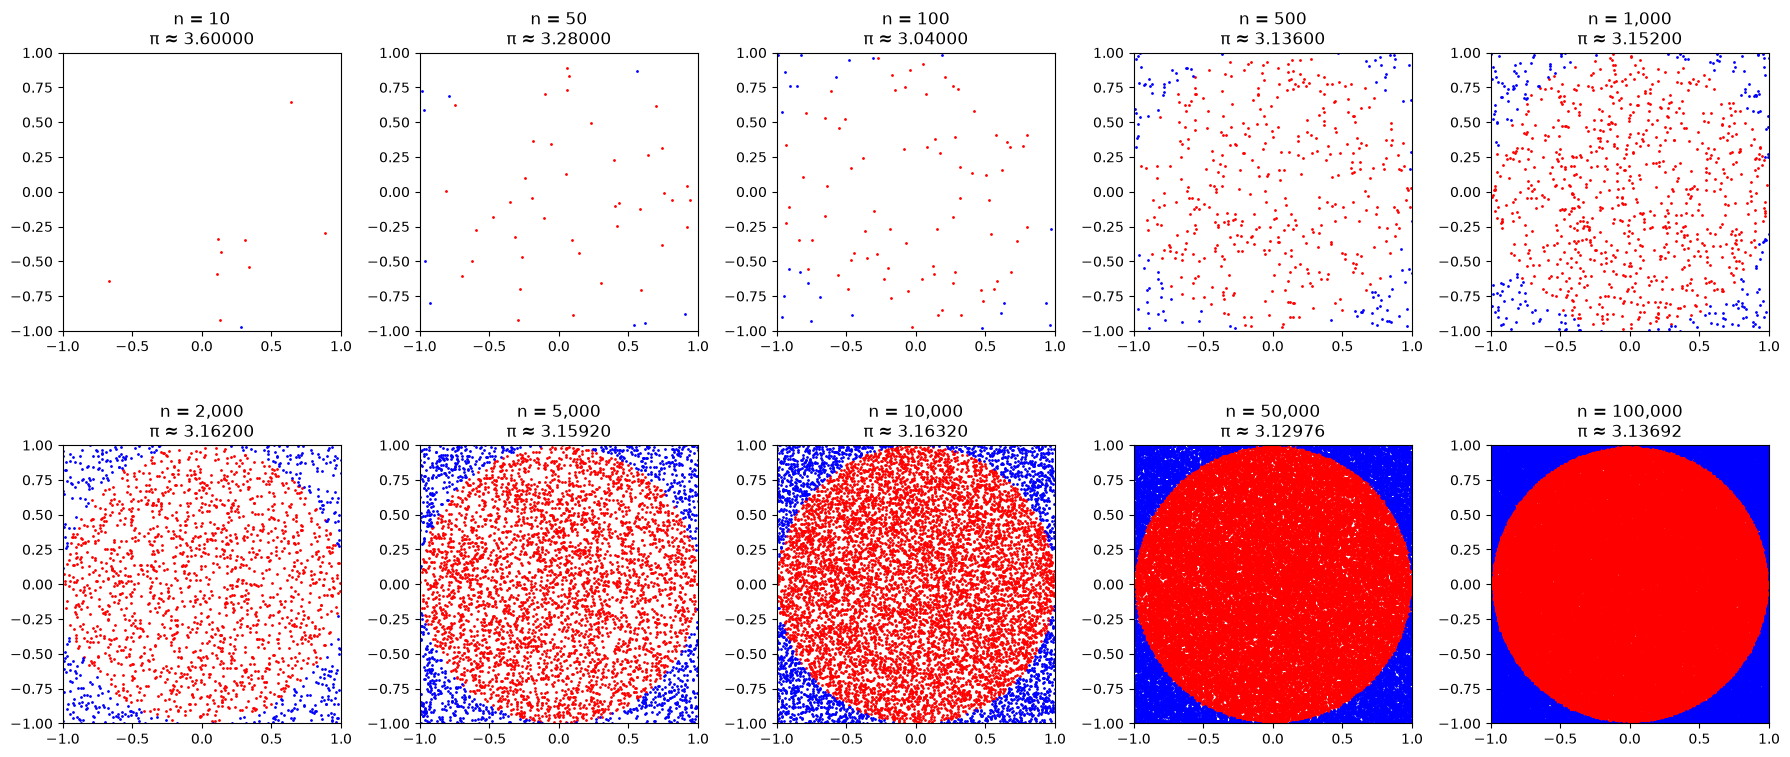

In [1]:
import random
import matplotlib.pyplot as plt

def estimate_pi(n):
    points_inside_circle = 0
    x_inside, y_inside = [], []
    x_outside, y_outside = [], []

    for _ in range(n):
        x = random.uniform(-1, 1)
        y = random.uniform(-1, 1)

        distance = x**2 + y**2

        if distance <= 1:
            points_inside_circle += 1
            x_inside.append(x)
            y_inside.append(y)
        else:
            x_outside.append(x)
            y_outside.append(y)

    pi = 4 * (points_inside_circle / n)

    return pi, x_inside, y_inside, x_outside, y_outside


# 점의 개수 (10단계)
num_points = [10, 50, 100, 500, 1000,
              2000, 5000, 10000, 50000, 100000]

# 2행 5열 Grid
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, n in zip(axes.flat, num_points):

    pi, xi, yi, xo, yo = estimate_pi(n)

    # 원 내부
    ax.scatter(xi, yi, s=1, c='red')

    # 원 외부
    ax.scatter(xo, yo, s=1, c='blue')

    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_aspect('equal')

    ax.set_title(f'n = {n:,}\nπ ≈ {pi:.5f}')

plt.tight_layout()
plt.show()

## 2. 평균의 증분 구현

In [2]:
import numpy as np

def sample(dices=2):
    x = 0
    for _ in range(dices):
        x += np.random.choice([1, 2, 3, 4, 5, 6])
    return x



[np.int64(7), np.int64(9), np.int64(6), np.int64(9), np.int64(4), np.int64(6), np.int64(7), np.int64(7), np.int64(8), np.int64(8), np.int64(7), np.int64(5), np.int64(3), np.int64(8), np.int64(8), np.int64(8), np.int64(7), np.int64(5), np.int64(10), np.int64(6), np.int64(9), np.int64(8), np.int64(10), np.int64(9), np.int64(4), np.int64(2), np.int64(9), np.int64(9), np.int64(10), np.int64(8), np.int64(8), np.int64(8), np.int64(10), np.int64(6), np.int64(8), np.int64(8), np.int64(10), np.int64(9), np.int64(10), np.int64(4), np.int64(7), np.int64(7), np.int64(5), np.int64(7), np.int64(9), np.int64(11), np.int64(5), np.int64(5), np.int64(3), np.int64(7), np.int64(9), np.int64(9), np.int64(5), np.int64(2), np.int64(6), np.int64(9), np.int64(8), np.int64(5), np.int64(6), np.int64(4), np.int64(9), np.int64(7), np.int64(8), np.int64(3), np.int64(6), np.int64(9), np.int64(7), np.int64(7), np.int64(7), np.int64(6), np.int64(10), np.int64(4), np.int64(5), np.int64(6), np.int64(6), np.int64(5), np.

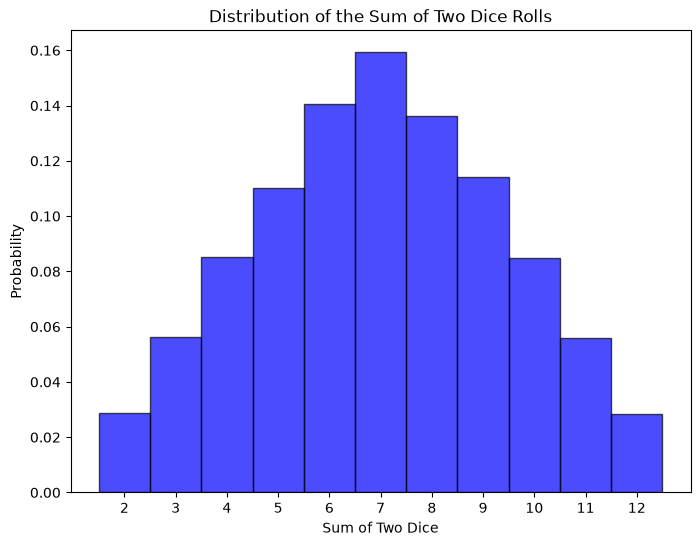

In [3]:
import matplotlib.pyplot as plt
samples = []
for _ in range(10000):
    samples.append(sample(2))

print(samples)

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(samples, bins=np.arange(2, 14) - 0.5,
        density=True, alpha=0.7, color='blue', edgecolor='black')
ax.set_xticks(range(2, 13))
ax.set_xlabel('Sum of Two Dice')
ax.set_ylabel('Probability')
ax.set_title('Distribution of the Sum of Two Dice Rolls')
plt.show()

### 1. 일반적인 평균 계산 방식 (Sample Average)

In [4]:
trial = 1000

samples = []
for _ in range(trial):
    s = sample()
    samples.append(s)
    V = sum(samples) / len(samples)  # 매번 평균 계산
    print(V)

2.0
5.0
6.333333333333333
6.25
5.8
6.333333333333333
6.571428571428571
7.0
6.666666666666667
6.9
6.909090909090909
6.833333333333333
6.6923076923076925
6.857142857142857
6.866666666666666
6.875
7.0
7.166666666666667
7.052631578947368
7.15
7.142857142857143
7.0
6.956521739130435
7.041666666666667
6.96
6.961538461538462
7.037037037037037
7.0
7.0344827586206895
7.133333333333334
7.096774193548387
7.09375
7.181818181818182
7.088235294117647
7.0
7.055555555555555
7.081081081081081
7.157894736842105
7.17948717948718
7.125
7.097560975609756
7.142857142857143
7.255813953488372
7.25
7.288888888888889
7.369565217391305
7.297872340425532
7.291666666666667
7.326530612244898
7.24
7.176470588235294
7.153846153846154
7.169811320754717
7.092592592592593
7.1454545454545455
7.178571428571429
7.175438596491228
7.103448275862069
7.101694915254237
7.05
7.032786885245901
7.016129032258065
7.063492063492063
7.078125
7.076923076923077
7.075757575757576
7.029850746268656
7.029411764705882
7.028985507246377
7.0

### 2. 점진적 평균 계산 방식 (Incremental Mean)

In [5]:
trial = 1000
V, n = 0, 0

for _ in range(trial):
    s = sample()
    n += 1
    V += (s - V) / n  # 또는 V = V + (s - V) / n
    print(V)

7.0
6.0
5.666666666666667
6.25
6.6
6.333333333333333
6.285714285714286
6.5
7.111111111111111
7.1
6.909090909090909
6.833333333333333
6.538461538461538
6.5
6.4
6.3125
6.411764705882353
6.611111111111112
6.894736842105264
7.000000000000001
6.952380952380953
6.818181818181819
6.8695652173913055
6.875000000000001
6.760000000000001
6.692307692307693
6.666666666666668
6.571428571428573
6.724137931034484
6.833333333333335
6.870967741935485
6.875000000000001
6.87878787878788
6.941176470588236
7.028571428571429
7.027777777777779
7.054054054054054
6.947368421052632
6.923076923076923
6.95
6.926829268292683
6.904761904761905
6.976744186046512
6.886363636363637
6.866666666666667
6.847826086956522
6.936170212765958
6.916666666666668
6.8775510204081645
6.960000000000001
6.882352941176471
6.846153846153847
6.867924528301887
6.851851851851852
6.836363636363637
6.857142857142858
6.912280701754386
6.9655172413793105
6.9491525423728815
6.95
7.016393442622951
7.064516129032258
7.0476190476190474
7.078125
7

## 3. 3×4 그리드 월드에서의 몬테카를로 정책 평가

원주율을 무작위 표본으로 추정한 것처럼, 강화학습에서는 정책에 따라 에피소드를 반복하고 관측한 반환값의 평균으로 상태 가치를 추정할 수 있습니다.

### 실험 설정

에이전트는 3×4 격자에서 네 가지 행동을 동일한 확률로 선택합니다. 목표 칸에 도착하면 \(+1\)의 보상을 받고 에피소드가 종료됩니다. 폭탄 칸에 도착하면 \(-1\)의 보상을 받지만, 에피소드는 계속됩니다. 가운데 칸은 벽이며, 할인율은 \($\gamma=0.9$\)입니다.

<img src="imgs/gridworld_3x4.png" alt="3×4 그리드 월드" width="300">

각 칸은 `(행, 열)` 좌표로 나타냅니다. 칸의 숫자는 해당 칸에 도착했을 때 받는 보상입니다.

<img src="imgs/gridworld_coordi.png" alt="보상 맵의 좌표계" width="300">



In [6]:
from collections import defaultdict
import numpy as np
# from dezerogym.gridworld import GridWorld

import dezerogym.gridworld_render as render_helper

class GridWorld:
    """결정적 전이 모델을 제공하는 3×4 그리드 월드."""

    def __init__(self):
        # 행동 공간과 행동의 의미
        self.action_space = [0, 1, 2, 3]
        self.action_meaning = {
            0: "UP",
            1: "DOWN",
            2: "LEFT",
            3: "RIGHT",
        }

        # 도착한 칸의 보상. None은 이동할 수 없는 벽이다.
        self.reward_map = np.array(
            [[0, 0, 0, 1.0],
             [0, None, 0, -1.0],
             [0, 0, 0, 0]]
        )
        # 목표, 벽, 시작 위치 (행, 열)
        self.goal_state = (0, 3)
        self.wall_state = (1, 1)
        self.start_state = (2, 0)
        self.agent_state = self.start_state  # 현재 에이전트 위치

    @property
    def height(self):  # 격자의 행 수
        return len(self.reward_map)

    @property
    def width(self):  # 격자의 열 수
        return len(self.reward_map[0])

    @property
    def shape(self):
        return self.reward_map.shape

    def actions(self):
        return self.action_space

    def states(self):
        # 시각화를 위한 전체 좌표를 반환한다. DP 계산에서는 벽을 제외한다.
        for h in range(self.height):
            for w in range(self.width):
                yield (h, w)

    def next_state(self, state, action):
        """에이전트를 움직이지 않고 다음 상태만 계산한다 (환경 모델)."""
        if state == self.goal_state:
            return state  # 종료 후에는 목표에 머무른다.
        # 행동별 (행, 열) 이동량: 위, 아래, 왼쪽, 오른쪽
        action_move_map = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        move = action_move_map[action]
        next_state = (state[0] + move[0], state[1] + move[1])
        ny, nx = next_state

        # 경계를 벗어나거나 벽이면 제자리에 머문다.
        if nx < 0 or nx >= self.width or ny < 0 or ny >= self.height:
            next_state = state
        elif next_state == self.wall_state:
            next_state = state

        return next_state

    def reward(self, state, action, next_state):
        # 목표로 들어갈 때 +1, 이미 종료된 후에는 추가 보상이 없다.
        if state == self.goal_state:
            return 0.0
        # 보상은 도착한 칸의 값 (폭탄 칸은 -1)
        return self.reward_map[next_state]

    def reset(self):
        # 시작 위치로 되돌린다.
        self.agent_state = self.start_state
        return self.agent_state

    def step(self, action):
        state = self.agent_state
        next_state = self.next_state(state, action)
        reward = self.reward(state, action, next_state)
        done = (next_state == self.goal_state)  # 목표 도달 시에만 종료

        self.agent_state = next_state
        return next_state, reward, done

    def render_v(self, v=None, policy=None, print_value=True):
        # 가치 함수(와 정책)를 격자 위에 시각화한다.
        renderer = render_helper.Renderer(self.reward_map, self.goal_state,
                                          self.wall_state)
        renderer.render_v(v, policy, print_value)


## 에이전트 

In [17]:

class RandomAgent:
    def __init__(self):
        self.gamma = 0.9
        self.action_size = 4
        # 균등 랜덤 정책:
        # 각 상태에서 네 가지 행동을 동일한 확률(0.25)로 선택
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.V = defaultdict(lambda: 0)
        self.cnts = defaultdict(lambda: 0)
        self.memory = []

    def get_action(self, state):
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        self.memory.clear()

    def eval(self):
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward
            self.cnts[state] += 1
            self.V[state] += (G - self.V[state]) / self.cnts[state]



### 1,000개의 에피소드를 수행한 뒤 추정한 상태 가치를 그리드에 시각화합니다.

In [21]:

env = GridWorld()
agent = RandomAgent()

episodes = 1000
for episode in range(episodes): # 에피소드 1000번 수행
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)  # 행동 선택
        print(f"Episode: {episode}, State: {state}, Action: {action}")

        next_state, reward, done = env.step(action) # 행동 수행

        agent.add(state, action, reward) # (상태, 행동, 보상) 저장
        if done: # 목표에 도달 시
            agent.eval() # 몬테카를로법으로 가치 함수 갱신
            break # 다음 에피소드 시작

        state = next_state

env.render_v(agent.V)

Episode: 0, State: (2, 0), Action: 1
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 3
Episode: 0, State: (2, 2), Action: 1
Episode: 0, State: (2, 2), Action: 1
Episode: 0, State: (2, 2), Action: 1
Episode: 0, State: (2, 2), Action: 1
Episode: 0, State: (2, 2), Action: 2
Episode: 0, State: (2, 1), Action: 1
Episode: 0, State: (2, 1), Action: 3
Episode: 0, State: (2, 2), Action: 1
Episode: 0, State: (2, 2), Action: 3
Episode: 0, State: (2, 3), Action: 3
Episode: 0, State: (2, 3), Action: 1
Episode: 0, State: (2, 3), Action: 0
Episode: 0, State: (1, 3), Action: 0


KeyboardInterrupt: 

<img src="imgs/dp_output.png" alt="동적 프로그래밍 결과" width="300">


동적프로그래밍(Dynamic Programming)으로 추정한 상태 가치와 비교하면, 몬테카를로 방법으로 추정한 상태 가치가 거의 동일함을 확인할 수 있습니다.

In [ ]:
from dezerogym.gridworld import GridWorld
from collections import defaultdict


def greedy_probs(Q, state, epsilon=0, action_size=4):
    # 현재 상태에서 각 행동의 행동 가치(Q)를 확인한다.
    qs = [Q[(state, action)] for action in range(action_size)]
    # Q값이 가장 큰 행동을 탐욕적으로 선택한다.
    max_action = np.argmax(qs)

    # 모든 행동에 탐험 확률을 균등하게 배분한다.
    base_prob = epsilon / action_size
    action_probs = {action: base_prob for action in range(action_size)}
    # 남은 확률을 가장 좋은 행동에 더한다.
    action_probs[max_action] += (1 - epsilon)
    return action_probs


class McAgent:
    def __init__(self):
        self.gamma = 0.9       # 할인율
        self.epsilon = 0.1     # 탐험 확률
        self.alpha = 0.1       # Q값 업데이트 학습률
        self.action_size = 4   # 행동의 개수

        # 초기에는 모든 행동을 같은 확률로 선택한다.
        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)  # 상태-행동 가치 함수
        self.memory = []                # 에피소드 경험 저장소

    def get_action(self, state):
        # 현재 상태의 정책에 따라 행동을 무작위로 선택한다.
        action_probs = self.pi[state]
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def add(self, state, action, reward):
        # 에피소드의 상태, 행동, 보상을 저장한다.
        data = (state, action, reward)
        self.memory.append(data)

    def reset(self):
        # 다음 에피소드를 위해 경험 저장소를 비운다.
        self.memory.clear()

    def update(self):
        # 에피소드 끝에서부터 거꾸로 반환값을 계산하고 Q를 갱신한다.
        G = 0
        for data in reversed(self.memory):
            state, action, reward = data
            G = self.gamma * G + reward

            # 학습률을 적용하여 행동가치함수 Q(s, a)를 갱신한다.
            key = (state, action)
            self.Q[key] += (G - self.Q[key]) * self.alpha

            # 갱신된 Q값을 바탕으로 ε-greedy 정책을 개선한다.
            self.pi[state] = greedy_probs(
                self.Q, state, self.epsilon, self.action_size
            )


Episode: 0, State: (2, 0), Action: 0
Episode: 0, State: (1, 0), Action: 1
Episode: 0, State: (2, 0), Action: 1
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 3
Episode: 0, State: (2, 2), Action: 2
Episode: 0, State: (2, 1), Action: 0
Episode: 0, State: (2, 1), Action: 0
Episode: 0, State: (2, 1), Action: 0
Episode: 0, State: (2, 1), Action: 2
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 2
Episode: 0, State: (2, 0), Action: 1
Episode: 0, State: (2, 0), Action: 1
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 1
Episode: 0, State: (2, 1), Action: 0
Episode: 0, State: (2, 1), Action: 2
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 2
Episode: 0, State: (2, 0), Action: 3
Episode: 0, State: (2, 1), Action: 0
Episode: 0, State: (2, 1), Action: 1
Episode: 0, State: (2, 1), Action: 2
Episode: 0, State: (2, 0), Action: 2
Episode: 0, State: (2, 0), Action: 2
Episode: 0, State: (2, 0), Action: 3
E

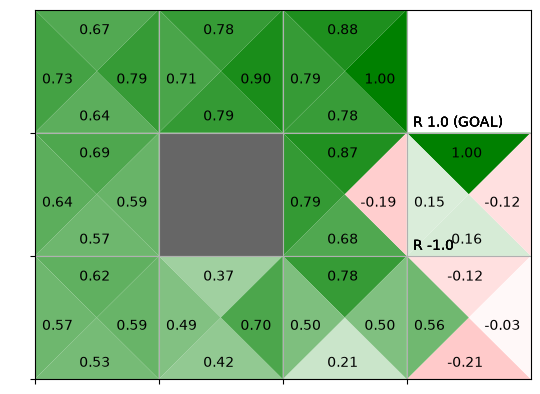

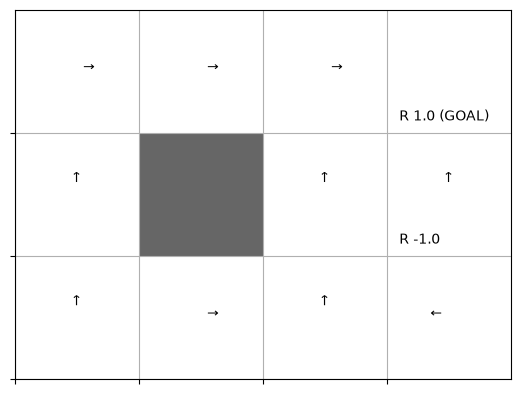

In [24]:
env = GridWorld()
agent = McAgent()

episodes = 10000
for episode in range(episodes):
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)
        print(f"Episode: {episode}, State: {state}, Action: {action}")
        next_state, reward, done = env.step(action)

        agent.add(state, action, reward)
        if done:
            agent.update()
            break

        state = next_state

env.render_q(agent.Q)